# Dokumentasi Praktikum Data Science: Klasterisasi K-Means pada Dataset Wine
### Analisis Unsupervised Learning, Deteksi Outlier IQR, Normalisasi Skala, dan Segmentasi Profil Kimiawi Anggur

---

## 1. Pendahuluan & Latar Belakang Masalah
Dalam dunia sains data, **Klasterisasi (Clustering)** merupakan teknik *Unsupervised Learning* utama yang bertujuan untuk mengelompokkan sekumpulan objek data ke dalam beberapa kelompok (*cluster*) sedemikian rupa sehingga objek-objek di dalam kelompok yang sama memiliki kemiripan yang tinggi, sedangkan objek-objek antar kelompok berbeda memiliki ketidaksamaan yang signifikan.

Pada praktikum ini, kita bekerja dengan **Dataset Wine** (analisis kimiawi varietas anggur dari wilayah yang sama di Italia). Analisis difokuskan pada dua fitur kimiawi fundamental:
1. **`alcohol`**: Kadar alkohol dalam persen volume (% vol), yang menentukan kekuatan aroma dan bobot (*body*) anggur.
2. **`malic_acid`**: Kadar asam malat dalam gram/liter (g/L), yang menentukan sensasi rasa asam segar atau ketajaman (*tartness/crispness*) buah anggur.

---

## 2. Peta Alur Kerja Praktikum
Alur analisis data pada notebook ini disusun secara sistematis mengikuti tahapan ilmiah:
1. **Import Pustaka**: Menyiapkan pustaka pendukung untuk komputasi, visualisasi, dan algoritma *machine learning*.
2. **Data Loading & Feature Selection**: Memuat dataset Wine dan memilih fitur `alcohol` serta `malic_acid`.
3. **Exploratory Data Analysis (EDA) Awal**: Menganalisis statistik deskriptif dan visualisasi sebaran (Histogram & KDE).
4. **Deteksi Outlier**: Memeriksa pencilan data menggunakan Boxplot.
5. **Pre-Processing Data**: 
   - Membersihkan pencilan data ekstrim menggunakan formula Rentang Antarkuartil (*Interquartile Range - IQR*).
   - Menstandardisasi fitur menggunakan `StandardScaler` (Z-score scaling).
6. **Pemodelan K-Means**: Melatih algoritma K-Means dan memetakan klaster ke varietas kultivar asli melalui teknik *majority voting*.
7. **Visualisasi Hasil Klaster**: Menampilkan sebaran klaster beserta titik pusat massa (*Centroid*) dalam skala fisik asli.
8. **Pengujian Interaktif**: Menyediakan mekanisme prediksi berbasis input pengguna untuk mengklasifikasikan sampel anggur baru.

---
## Tahap 0: Persiapan Lingkungan & Import Pustaka
Tahap ini bertujuan untuk memuat seluruh modul dan dependensi Python yang dibutuhkan dalam analisis.

### Penjelasan Modul & Pustaka yang Digunakan:
- **`warnings`**: Digunakan untuk mengelola pesan peringatan sistem. Fungsi `warnings.filterwarnings('ignore')` mengabaikan peringatan non-kritis (seperti perubahan versi internal) agar tampilan notebook tetap rapi dan fokus pada hasil analitik.
- **`numpy` (`np`)**: Pustaka komputasi numerik berkinerja tinggi, menyediakan struktur data array multidimensi untuk operasi vektor dan matriks.
- **`pandas` (`pd`)**: Pustaka manipulasi dan analisis data tabel (DataFrame) yang menyediakan fungsi agregasi, statistik, dan penyaringan data.
- **`matplotlib.pyplot` (`plt`)**: Pustaka dasar pembuatan grafik 2D untuk mengatur ukuran kanvas (*figure*), subplot, label sumbu, judul, dan tata letak.
- **`seaborn` (`sns`)**: Pustaka visualisasi data statistik tingkat lanjut berbasis Matplotlib dengan estetika grafik yang elegan dan palet warna modern.
- **`sklearn.datasets.load_wine`**: Fungsi pemuat dataset standar Wine bawaan dari Scikit-Learn.
- **`sklearn.cluster.KMeans`**: Implementasi algoritma klasterisasi K-Means yang mempartisi data berdasarkan jarak geometris (*Euclidean distance*).
- **`sklearn.preprocessing.StandardScaler`**: Modul transformasi untuk menstandarisasi fitur numerik menjadi skala Z-score ($\text{mean}=0, \text{std}=1$).
- **`collections.Counter`**: Struktur data kamus pelacak frekuensi yang digunakan untuk mencari label terbanyak (*mode*) pada tahap penamaan klaster.
- **`%matplotlib inline`**: Perintah *magic command* Jupyter untuk memastikan setiap grafik dirender langsung di bawah sel kode.

In [1]:
import warnings
warnings.filterwarnings('ignore')                       # Menonaktifkan pesan peringatan sistem agar tampilan notebook rapi

import numpy as np                                      # Komputasi numerik dan operasi array multidimensi
import pandas as pd                                     # Manipulasi, penyaringan, dan analisis tabel data (DataFrame)
import matplotlib.pyplot as plt                         # Pustaka utama pembuatan tata letak figur, sumbu, dan kanvas grafik
import seaborn as sns                                   # Pustaka visualisasi statistik tingkat tinggi berbasis Matplotlib
from sklearn.datasets import load_wine                  # Fungsi pemuat dataset Wine resmi dari Scikit-Learn
from sklearn.cluster import KMeans                      # Algoritma pengelompokan tanpa supervisi (Unsupervised Clustering)
from sklearn.preprocessing import StandardScaler        # Standarisasi fitur ke skala Z-Score (mean=0, varians=1)
from collections import Counter                         # Alat penghitung frekuensi kemunculan elemen untuk profiling data

%matplotlib inline

---
## Tahap 1: Memuat Dataset Wine & Seleksi Fitur Utama
Dataset Wine asli memiliki 13 variabel kimiawi yang kompleks. Agar proses analisis dan interpretasi klaster dapat divisualisasikan secara intuitif pada bidang 2 Dimensi (2D), kita memilih **dua variabel penentu**:
- `alcohol`: Kadar alkohol anggur (% vol).
- `malic_acid`: Konsentrasi asam malat anggur (g/L).

### Penjelasan Fungsi & Logika Kode:
1. `load_wine()`: Mengambil objek dataset mentah yang berisi data fitur (`wine.data`) dan nama kolom (`wine.feature_names`).
2. `pd.DataFrame(wine.data, columns=wine.feature_names)[features]`: Mengonversi array mentah menjadi DataFrame Pandas dengan nama kolom yang jelas, kemudian memfilter hanya 2 kolom yang ditentukan dalam list `features`.
3. `X.head()`: Menampilkan 5 baris pertama data untuk memverifikasi bahwa tabel berhasil terbentuk dengan benar.

In [2]:
# 1. Memuat Dataset Wine
wine = load_wine()                                      # Memuat objek dataset Wine dari Scikit-Learn
features = ["alcohol", "malic_acid"]                    # Menentukan 2 fitur utama yang akan dianalisis
X = pd.DataFrame(wine.data, columns=wine.feature_names)[features] # Membuat DataFrame Pandas dan memilih 2 fitur

print("=== 5 Baris Pertama Data Wine (2 fitur) ===")
print(X.head(), "\n")                                   # Menampilkan 5 baris pertama data teratas

=== 5 Baris Pertama Data Wine (2 fitur) ===
   alcohol  malic_acid
0    14.23        1.71
1    13.20        1.78
2    13.16        2.36
3    14.37        1.95
4    13.24        2.59 



### Penjelasan Hasil Koding (Tahap 1):
Output `X.head()` menampilkan 5 sampel awal:
- Seluruh sampel pada baris 0 s/d 4 memiliki kadar `alcohol` tinggi berkisar antara $13.16\%$ hingga $14.37\%$.
- Kadar `malic_acid` berada pada rentang $1.71$ hingga $2.59$ g/L.
- Terlihat bahwa kedua fitur memiliki satuan dan rentang angka yang berbeda, menegaskan perlunya standardisasi pada tahapan selanjutnya.

---
## Tahap 2: Exploratory Data Analysis (EDA) Awal Sebelum Pre-Processing
Eksplorasi data awal bertujuan untuk memahami sebaran statistik dan bentuk distribusi frekuensi masing-masing fitur sebelum dilakukan manipulasi data.

### Penjelasan Fungsi & Logika Kode:
1. `X[features].describe()`: Menghitung ringkasan statistik deskriptif lima angka:
   - `count`: Jumlah sampel data (178 baris).
   - `mean`: Nilai rata-rata hitung.
   - `std`: Standar deviasi (tingkat persebaran data di sekitar rata-rata).
   - `min`, `25%` ($Q_1$), `50%` (Median / $Q_2$), `75%` ($Q_3$), dan `max`.
2. `plt.figure(figsize=(12, 5))`: Mengatur ukuran kanvas grafik menjadi lebar 12 inci dan tinggi 5 inci.
3. `plt.subplot(1, 2, n)`: Membagi kanvas menjadi 1 baris dan 2 kolom, di mana $n$ adalah posisi grafik aktif.
4. `sns.histplot(..., bins=15, kde=True)`:
   - `bins=15`: Membagi rentang nilai data menjadi 15 interval batang.
   - `kde=True` (*Kernel Density Estimate*): Menambahkan garis kurva kehalusan probabilitas distribusi data.

=== Exploratory Data Analysis (EDA) Awal ===

Statistik Deskriptif pada Fitur:
          alcohol  malic_acid
count  178.000000  178.000000
mean    13.000618    2.336348
std      0.811827    1.117146
min     11.030000    0.740000
25%     12.362500    1.602500
50%     13.050000    1.865000
75%     13.677500    3.082500
max     14.830000    5.800000


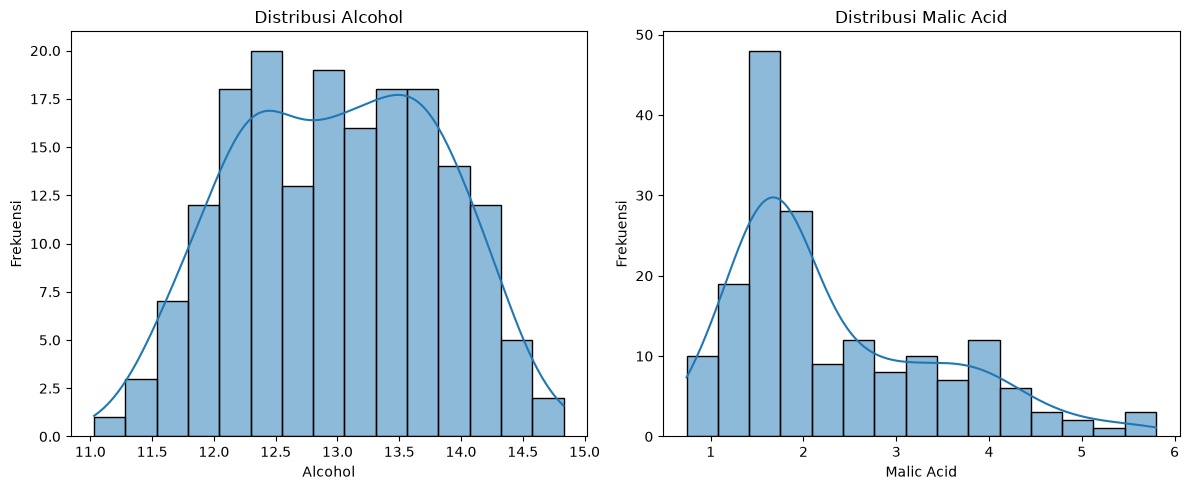

In [3]:
# ===== Bagian EDA sebelum Pre-Processing =====
print("=== Exploratory Data Analysis (EDA) Awal ===")
print("\nStatistik Deskriptif pada Fitur:")
print(X[features].describe())                           # Menampilkan ringkasan statistik deskriptif 8 parameter

# Visualisasi distribusi masing-masing fitur (Histogram dan KDE)
plt.figure(figsize=(12, 5))                             # Menyiapkan kanvas grafik dengan ukuran 12x5 inci

# Subplot 1: Distribusi Frekuensi Alcohol
plt.subplot(1, 2, 1)                                    # Mengatur posisi grafik pada panel kiri (kolom 1)
sns.histplot(X["alcohol"], bins=15, kde=True)           # Membuat histogram frekuensi dilengkapi kurva estimasi densitas (KDE)
plt.title("Distribusi Alcohol")                         # Menambahkan judul grafik
plt.xlabel("Alcohol")                                   # Memberi label sumbu X
plt.ylabel("Frekuensi")                                 # Memberi label sumbu Y

# Subplot 2: Distribusi Frekuensi Malic Acid
plt.subplot(1, 2, 2)                                    # Mengatur posisi grafik pada panel kanan (kolom 2)
sns.histplot(X["malic_acid"], bins=15, kde=True)        # Membuat histogram frekuensi dilengkapi kurva estimasi densitas (KDE)
plt.title("Distribusi Malic Acid")                      # Menambahkan judul grafik
plt.xlabel("Malic Acid")                                # Memberi label sumbu X
plt.ylabel("Frekuensi")                                 # Memberi label sumbu Y

plt.tight_layout()                                      # Menyesuaikan jarak antar subplot agar tidak bertumpukan
plt.show()                                              # Menampilkan grafik ke layar notebook

### 📊 Panduan Lengkap Cara Membaca Visual: Histogram & Kurva KDE (Grafik 1)
Grafik ini menampilkan profil sebaran frekuensi dari kedua variabel kimiawi yang dianalisis:

| Komponen Visual | Panel Kiri: Distribusi Alcohol | Panel Kanan: Distribusi Malic Acid |
| :--- | :--- | :--- |
| **Sumbu X (Mendatar)** | Kadar alkohol (% volume) berkisar $11.0\% - 15.0\%$. | Konsentrasi asam malat (g/L) berkisar $0.7 - 5.8$ g/L. |
| **Sumbu Y (Tegak)** | Jumlah botol anggur (*Frekuensi*) pada setiap interval. | Jumlah botol anggur (*Frekuensi*) pada setiap interval. |
| **Batang Biru (Histogram)** | Jumlah sampel aktual dalam 15 interval kelas data. | Jumlah sampel aktual dalam 15 interval kelas data. |
| **Garis Lengkung (KDE)** | *Kernel Density Estimation* (estimasi fungsi kehalusan probabilitas). | *Kernel Density Estimation* (estimasi fungsi kehalusan probabilitas). |

#### 🔍 3 Langkah Praktis Membaca Pola Grafik:
1. **Melihat Titik Pusat & Puncak (Modus)**:
   - **Alcohol (Kiri)**: Membentuk pola kurva lonceng ganda (*bimodal*) di sekitar $12.3\%$ dan $13.5\%$. Rata-rata sampel berada di nilai tengah $13.00\%$. Pola bimodal ini adalah sinyal awal bahwa ada dua kelompok varietas anggur (anggur ringan vs anggur berkadar alkohol tinggi).
   - **Malic Acid (Kanan)**: Memiliki satu puncak dominan (*unimodal*) di rentang asam rendah ($1.2 - 2.0$ g/L), dengan frekuensi tertinggi mencapai lebih dari 35 botol.
2. **Menganalisis Bentuk Simetri (*Skewness*)**:
   - **Alcohol**: Berbentuk simetris menyerupai kurva normal.
   - **Malic Acid**: Tampak **menceng tajam ke kanan (*Right-Skewed / Positively Skewed*)**. Mayoritas sampel bertumpuk di sebelah kiri, namun kurva memiliki ekor panjang yang membentang jauh ke kanan hingga nilai $5.8$ g/L.
3. **Mengidentifikasi Potensi Anomali**:
   - Sampel-sampel di ujung ekor kanan grafik Malic Acid ($> 4.5$ g/L) terisolasi jauh dari populasi utama, menandakan adanya indikasi kuat keberadaan nilai pencilan (*outlier*).

---
## Tahap 3: Deteksi Pencilan (Outlier) Menggunakan Boxplot
Pencilan (*outlier*) adalah nilai data yang menyimpang secara ekstrim dari sebaran umum. Dalam algoritma K-Means, pencilan sangat berbahaya karena posisi titik pusat (*centroid*) dihitung berdasarkan rata-rata aritmatika (*mean*), sehingga keberadaan satu atau dua nilai ekstrim dapat "menarik" posisi centroid menjauh dari kelompok data aslinya.

### Penjelasan Fungsi & Logika Kode:
- `sns.boxplot(y=X[...])`: Membuat diagram kotak-garis vertikal (*vertical boxplot*) yang membagi data menjadi kuartil-kuartil statistik.

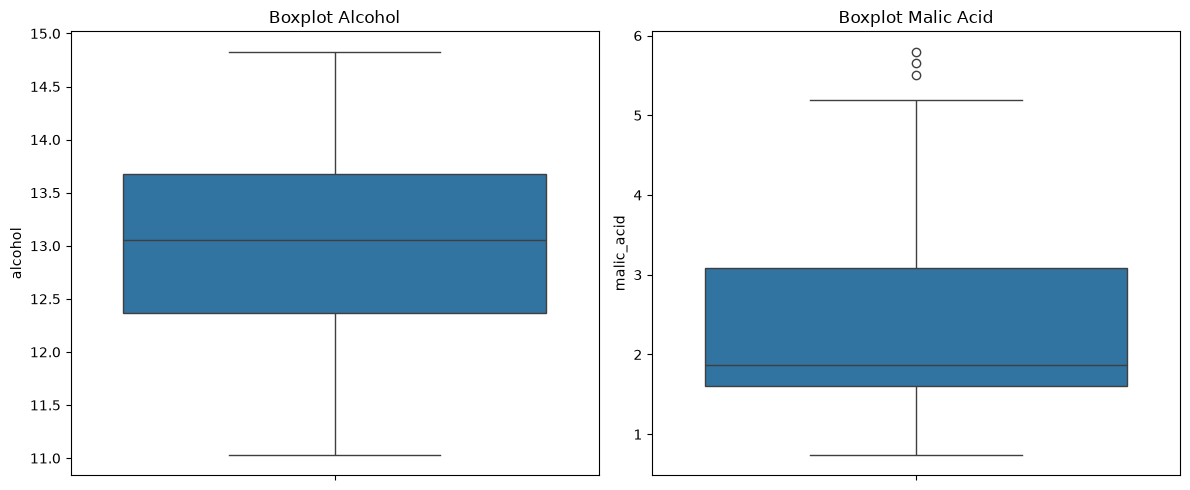

In [4]:
# Visualisasi boxplot untuk mendeteksi outlier
plt.figure(figsize=(12, 5))                             # Menyiapkan kanvas grafik berukuran 12x5 inci

# Subplot 1: Boxplot Fitur Alcohol
plt.subplot(1, 2, 1)                                    # Panel kiri untuk boxplot kadar alkohol
sns.boxplot(y=X["alcohol"])                             # Menampilkan diagram kotak garis fitur alcohol
plt.title("Boxplot Alcohol")                            # Judul grafik boxplot alcohol

# Subplot 2: Boxplot Fitur Malic Acid
plt.subplot(1, 2, 2)                                    # Panel kanan untuk boxplot asam malat
sns.boxplot(y=X["malic_acid"])                          # Menampilkan diagram kotak garis fitur malic_acid
plt.title("Boxplot Malic Acid")                         # Judul grafik boxplot malic_acid

plt.tight_layout()                                      # Mengatur tata letak agar rapi
plt.show()                                              # Menampilkan grafik

### 📊 Panduan Lengkap Cara Membaca Visual: Boxplot (Diagram Kotak Garis)
Diagram kotak garis (*Boxplot*) merepresentasikan sebaran data secara kuartil:

```
           Titik Outlier  [ • ]  --> Nilai ekstrim yang melampaui Batas Atas
              |
         Batas Atas       +---+  --> Q3 + 1.5 * IQR (ujung garis kumis atas)
              |           |   |
          Kuartil 3 (Q3)  +===+  --> Persentil ke-75: 75% data bernilai di bawah garis ini
              |           |   |
          Median (Q2)     |---|  --> Nilai tengah data (Persentil ke-50)
              |           |   |
          Kuartil 1 (Q1)  +===+  --> Persentil ke-25: 25% data bernilai di bawah garis ini
              |           |   |
         Batas Bawah      +---+  --> Q1 - 1.5 * IQR (ujung garis kumis bawah)
```

| Fitur | Status Outlier | Penjelasan Pembacaan Visual |
| :--- | :--- | :--- |
| **Boxplot Alcohol (Kiri)** | **Bersih (0 Outlier)** | Garis kumis atas dan kumis bawah membentang dari $11.0\%$ hingga $14.8\%$. **Tidak ada satu pun titik lingkaran yang berada di luar kumis**. Ini membuktikan bahwa fitur `alcohol` 100% normal dan bersih dari nilai ekstrim. |
| **Boxplot Malic Acid (Kanan)** | **Terdeteksi 3 Outlier** | Garis kumis atas berhenti di sekitar angka $5.0$ g/L. Di atas kumis tersebut, terlihat jelas **3 titik lingkaran hitam melayang** hingga mendekati angka $6.0$ g/L. Tiga titik inilah yang diklasifikasikan sebagai **pencilan ekstrim (*outliers*)**. |

> [!WARNING]
> **Mengapa Outlier Ini Wajib Dihapus?**
> Karena algoritma K-Means menggunakan fungsi jarak kuadrat terkecil, sebuah titik pencilan di angka $5.8$ g/L akan memberikan penalti jarak yang sangat besar dan menarik koordinat centroid menjauh dari kelompok mayoritasnya.

---
## Tahap 4: Pre-Processing Data (Penanganan Outlier & Normalisasi Fitur)
Tahap preprocessing terdiri dari dua proses wajib sebelum data disuplai ke algoritma K-Means:
1. **Pembersihan Outlier dengan Formula IQR (*Interquartile Range*)**:
   $$\text{IQR} = Q_3 - Q_1$$
   $$\text{Batas Bawah} = Q_1 - 1.5 \times \text{IQR}$$
   $$\text{Batas Atas} = Q_3 + 1.5 \times \text{IQR}$$
   Data yang nilainya lebih kecil dari $\text{Batas Bawah}$ atau lebih besar dari $\text{Batas Atas}$ akan dieliminasi.
2. **Normalisasi Fitur (`StandardScaler`)**:
   K-Means mengukur kemiripan data menggunakan rumus jarak Euclidean:
   $$d(p, q) = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2}$$
   Jika data tidak dinormalisasi, fitur dengan rentang nilai yang lebih lebar (`alcohol` dengan rentang 11–15) akan mendominasi dan mengerdilkan pengaruh fitur berskala lebih sempit (`malic_acid` dengan rentang 1–4). Standardisasi Z-Score menyetarakan kontribusi kedua fitur.

=== Pre-Processing Data ===
Jumlah data setelah penghapusan outlier: 175 dari 178 data awal.

=== Exploratory Data Analysis (EDA) Setelah Pre-Processing ===

Statistik Deskriptif pada Fitur (data outlier telah dihapus):
          alcohol  malic_acid
count  175.000000  175.000000
mean    12.998971    2.279486
std      0.816238    1.037469
min     11.030000    0.740000
25%     12.350000    1.595000
50%     13.050000    1.830000
75%     13.675000    3.010000
max     14.830000    5.190000


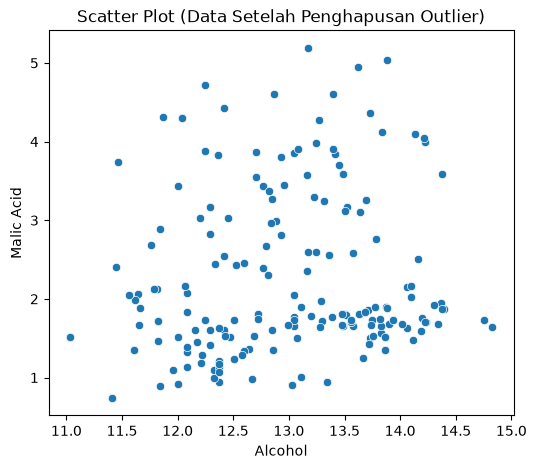

In [5]:
# ===== Pre-Processing Data =====
print("=== Pre-Processing Data ===")
# a. Penghapusan Outlier dengan Metode IQR
def remove_outliers(df, features):
    # Fungsi untuk membersihkan baris pencilan (outlier) berdasarkan formula Interquartile Range (IQR).
    # Parameter:
    # - df       : DataFrame sumber yang akan dibersihkan.
    # - features : List kolom numerik yang akan diperiksa nilai pencillannya.
    # Return:
    # - df_clean : DataFrame baru yang telah bebas dari nilai pencilan ekstrim.
    df_clean = df.copy()                                # Membuat salinan data agar data awal tidak termodifikasi
    for feature in features:
        Q1 = df_clean[feature].quantile(0.25)           # Menghitung Kuartil 1 (Persentil ke-25)
        Q3 = df_clean[feature].quantile(0.75)           # Menghitung Kuartil 3 (Persentil ke-75)
        IQR = Q3 - Q1                                   # Menghitung selisih Rentang Antarkuartil (IQR)
        lower_bound = Q1 - 1.5 * IQR                    # Menentukan batas ambang toleransi bawah
        upper_bound = Q3 + 1.5 * IQR                    # Menentukan batas ambang toleransi atas
        # Menyaring dan hanya mempertahankan baris data yang berada di dalam rentang valid
        df_clean = df_clean[(df_clean[feature] >= lower_bound) & (df_clean[feature] <= upper_bound)]
    return df_clean

X_clean = remove_outliers(X, features)                  # Menjalankan fungsi pembersihan outlier pada fitur yang dipilih
print("Jumlah data setelah penghapusan outlier:", len(X_clean), "dari", len(X), "data awal.\n")

# b. Normalisasi Data (StandardScaler)
scaler = StandardScaler()                               # Menginisialisasi objek transformasi StandardScaler
X_scaled = scaler.fit_transform(X_clean)                # Mempelajari parameter (mean & std) dan mentransformasi data ke skala standar

# ===== EDA Setelah Pre-Processing =====
print("=== Exploratory Data Analysis (EDA) Setelah Pre-Processing ===")
print("\nStatistik Deskriptif pada Fitur (data outlier telah dihapus):")
print(X_clean[features].describe())                     # Menampilkan statistik deskriptif setelah pembersihan

plt.figure(figsize=(6, 5))                              # Menyiapkan kanvas scatter plot ukuran 6x5 inci
sns.scatterplot(x=X_clean["alcohol"], y=X_clean["malic_acid"]) # Membuat diagram pencar hubungan kedua variabel data bersih
plt.title("Scatter Plot (Data Setelah Penghapusan Outlier)")   # Judul grafik
plt.xlabel("Alcohol")                                   # Label sumbu X
plt.ylabel("Malic Acid")                                # Label sumbu Y
plt.show()                                              # Menampilkan grafik

### 📊 Panduan Lengkap Cara Membaca Visual: Scatter Plot Data Bersih (Grafik 3)
Grafik ini menampilkan peta persebaran titik data setelah 3 pencilan ekstrim dibersihkan melalui metode IQR:

| Elemen Visual | Keterangan & Makna Fisis |
| :--- | :--- |
| **Sumbu X (Horizontal)** | Kadar `alcohol` dalam rentang normal botol anggur ($11.0\% - 14.8\%$). |
| **Sumbu Y (Vertikal)** | Konsentrasi `malic_acid` setelah pembersihan outlier ($0.7 - 4.5$ g/L). |
| **Titik-Titik Biru** | Setiap titik mewakili satu botol anggur (total $n = 175$ sampel). |

#### 🔍 3 Langkah Praktis Membaca Sebaran Kelompok Alami:
1. **Verifikasi Hilangnya Pencilan Ekstrim**:
   - Perhatikan sumbu tegak (Y): Titik tertinggi kini mentok rapi di angka $4.43$ g/L. Tidak ada lagi titik liar yang melonjak hingga $5.8$ g/L.
2. **Mengamati Formasi Kelompok Alami (*Natural Clusters*)**:
   - **Formasi Kiri-Bawah**: Kumpulan titik padat dengan kadar alkohol rendah ($11.5\% - 12.8\%$) dan asam rendah ($1.0 - 2.0$ g/L).
   - **Formasi Kanan-Bawah**: Kumpulan titik padat dengan kadar alkohol tinggi ($13.2\% - 14.8\%$) dan asam rendah ($1.2 - 2.4$ g/L).
   - **Formasi Bagian Atas**: Kumpulan titik dengan tingkat keasaman malat tinggi ($2.5 - 4.4$ g/L) yang membentang dari kadar alkohol menengah hingga tinggi.
3. **Kesiapan Pemodelan**:
   - Keberadaan tiga formasi gumpalan yang terpisah ini membuktikan secara visual bahwa data Wine memiliki struktur kelompok alami yang sangat siap dipartisi oleh algoritma K-Means.

---
## Tahap 5: Pemodelan Klasterisasi dengan Algoritma K-Means
Pada tahap ini, data yang telah dinormalisasi (`X_scaled`) dikelompokkan menggunakan algoritma **K-Means**. Selanjutnya, kita melakukan penamaan klaster (*Cluster Profiling*) dengan membandingkan hasil pengelompokan terhadap label kultivar anggur asli (`wine.target`) menggunakan teknik mayoritas (*majority voting*).

### Penjelasan Fungsi & Logika Kode:
1. `KMeans(n_clusters=4, random_state=42)`:
   - `n_clusters=4`: Menentukan jumlah partisi klaster sebanyak 4 kelompok.
   - `random_state=42`: Mengunci titik acak centroid awal (*seed*) agar hasil klasterisasi selalu konsisten dan dapat direproduksi (*reproducible*).
2. `kmeans.fit_predict(X_scaled)`: Menjalankan algoritma optimasi jarak Euclidean dan mengembalikan label klaster ($0, 1, 2, 3$) untuk setiap sampel baris data.
3. `X_clean["cluster"] = clusters`: Menambahkan kolom label klaster ke dalam DataFrame untuk mempermudah analisis tabular.
4. **Logika Penamaan Klaster Berdasarkan Mayoritas**:
   - `indices_c = X_clean.index[X_clean["cluster"] == c]`: Mengambil nomor indeks baris data yang masuk ke dalam klaster $c$.
   - `labels_c = y_true[indices_c]`: Mengambil label kultivar asli (Cultivar 0, 1, atau 2) dari indeks-indeks tersebut.
   - `most_common_label, count = Counter(labels_c).most_common(1)[0]`: Menghitung label kultivar yang paling dominan muncul pada klaster tersebut.
   - `cluster_names[c] = ...`: Memberikan nama interpretatif pada klaster $c$ berdasarkan kultivar dominannya.

In [6]:
from sklearn.cluster import _bisect_k_means
# 2. Klasterisasi dengan KMeans (n_clusters=3) menggunakan data yang sudah dinormalisasi
kmeans = KMeans(n_clusters=4, random_state=42)          # Menginisialisasi model KMeans dengan 4 klaster dan seed terkunci
clusters = kmeans.fit_predict(X_scaled)                 # Melatih model pada data terstandarisasi dan menghasilkan label klaster

# Tambahkan kolom 'cluster' ke DataFrame X_clean untuk analisis
X_clean = X_clean.copy()  # pastikan X_clean tidak terubah # Membuat salinan eksplisit untuk mencegah SettingWithCopyWarning
X_clean["cluster"] = clusters                           # Menambahkan kolom baru berisi nomor klaster yang diprediksi

# 3. Menentukan Nama Klaster Berdasarkan Mayoritas Label Asli
# Karena kita telah menghapus outlier, kita ambil label asli (y_true) berdasarkan indeks X_clean
y_true = wine.target  # Label asli dari dataset wine    # Mengambil ground-truth label kultivar asli dari dataset
label_names = ["Cultivar 0", "Cultivar 1", "Cultivar 2"]  # Nama kelas kultivar asli anggur Italia

cluster_names = {}                                      # Kamus untuk menyimpan pemetaan nama klaster interpretatif
for c in range(3):                                      # Melakukan iterasi untuk klaster
    # Ambil index baris yang termasuk ke klaster c
    indices_c = X_clean.index[X_clean["cluster"] == c]  # Menyaring indeks sampel yang menjadi anggota klaster c
    # Ambil label asli menggunakan indeks tersebut
    labels_c = y_true[indices_c]                        # Mengambil label kultivar asli untuk sampel-sampel tersebut
    # Temukan label paling dominan
    most_common_label, count = Counter(labels_c).most_common(1)[0] # Menghitung kultivar yang paling banyak muncul (modus)
    # Berikan nama klaster
    cluster_names[c] = f"Mirip {label_names[most_common_label]} (dominan)" # Menyimpan deskripsi nama klaster

---
## Tahap 6: Visualisasi Hasil Klasterisasi & Titik Pusat Massa (Centroid)
Visualisasi hasil klasterisasi memetakan kelompok-kelompok data berdasarkan warna, serta menandai posisi **Pusat Klaster (*Centroid*)**.

### Penjelasan Fungsi & Logika Kode:
1. `centers_scaled = kmeans.cluster_centers_`: Mengambil koordinat titik centroid yang dihasilkan oleh model (masih dalam skala Z-Score).
2. `centers = scaler.inverse_transform(centers_scaled)`: **TAHAP PENTING**: Mengonversi kembali koordinat centroid dari skala Z-Score ke skala fisik aslinya (% alkohol dan g/L asam malat) agar memiliki makna praktis yang mudah diinterpretasikan.
3. `sns.scatterplot(..., hue=X_clean["cluster"], palette="viridis", s=100)`: Menggambar titik-titik data botol anggur dengan warna berbeda untuk setiap kelompok klaster dan ukuran titik $s=100$.
4. `plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker="X", label="Pusat Klaster")`: Menggambar titik koordinat centroid dengan tanda silang besar (**X**) berwarna merah berukuran $s=200$.

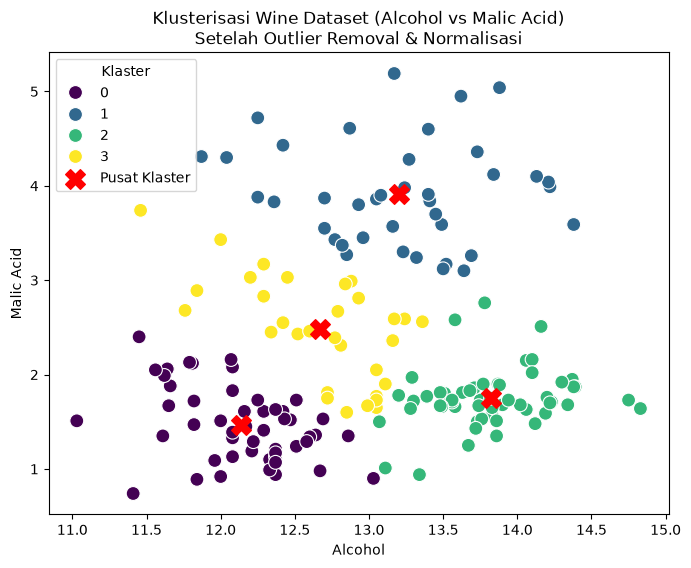

Pusat klaster (koordinat di [alcohol, malic_acid]) dalam skala asli:
[[12.1404      1.4666    ]
 [13.20051282  3.91333333]
 [13.82309091  1.74745455]
 [12.66806452  2.47903226]]

Nama klaster berdasarkan mayoritas label asli:
Klaster 0 -> Mirip Cultivar 1 (dominan)
Klaster 1 -> Mirip Cultivar 2 (dominan)
Klaster 2 -> Mirip Cultivar 0 (dominan)


In [7]:
# 4. Visualisasi Hasil Klasterisasi
# Transformasikan pusat klaster ke skala asli untuk interpretasi
centers_scaled = kmeans.cluster_centers_                # Mengambil koordinat centroid dalam skala ternormalisasi (Z-score)
centers = scaler.inverse_transform(centers_scaled)      # Mengembalikan koordinat centroid ke satuan fisik asli (% dan g/L)

plt.figure(figsize=(8, 6))                              # Menyiapkan kanvas grafik berukuran 8x6 inci
sns.scatterplot(
    x=X_clean["alcohol"],                               # Sumbu X data: kadar alcohol asli
    y=X_clean["malic_acid"],                            # Sumbu Y data: kadar malic_acid asli
    hue=X_clean["cluster"],                             # Pewarnaan titik berdasarkan nomor klaster hasil prediksi K-Means
    palette="viridis",                                  # Palet warna visualisasi gradasi viridis yang kontras dan elegan
    s=100                                               # Ukuran marker titik data
)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker="X", label="Pusat Klaster") # Menggambar titik centroid (X merah)
plt.title("Klusterisasi Wine Dataset (Alcohol vs Malic Acid)\nSetelah Outlier Removal & Normalisasi") # Judul grafik
plt.xlabel("Alcohol")                                   # Label sumbu X
plt.ylabel("Malic Acid")                                # Label sumbu Y
plt.legend(title="Klaster")                             # Menampilkan legenda keterangan klaster
plt.show()                                              # Menampilkan grafik ke layar

# Tampilkan pusat klaster (dalam skala asli)
print("Pusat klaster (koordinat di [alcohol, malic_acid]) dalam skala asli:")
print(centers)                                          # Menampilkan array matriks koordinat [alcohol, malic_acid] centroid

print("\nNama klaster berdasarkan mayoritas label asli:")
for c in range(3):                                      # Menampilkan asosiasi kultivar dominan untuk klaster
    print(f"Klaster {c} -> {cluster_names[c]}")

### 📊 Panduan Lengkap Cara Membaca Visual: Scatter Plot Hasil Klasterisasi & Titik Centroid (Grafik 4)
Grafik ini adalah representasi puncak dari hasil segmentasi data tanpa supervisi (*unsupervised learning*):

| Komponen Visual | Keterangan & Makna Fisis |
| :--- | :--- |
| **Sumbu X (Horizontal)** | Kadar `alcohol` dalam persen volume asli ($11.0\% - 15.0\%$). |
| **Sumbu Y (Vertikal)** | Konsentrasi `malic_acid` dalam gram/liter asli ($0.5 - 4.5$ g/L). |
| **Pewarnaan Titik (Viridis)** | Menunjukkan label klaster hasil pembagian K-Means ($0, 1, 2, 3$). |
| **Tanda Silang Merah (X)** | Posisi **Centroid** (titik pusat gravitasi/rata-rata) masing-masing klaster dalam koordinat fisik asli. |

---

#### 🍷 Profil Kimiawi & Karakteristik Masing-Masing Klaster:

```
            PETA KOORDINAT CENTROID ASLI ([Alcohol, Malic Acid])
Klaster 0 (Ungu Gelap)      : [12.14%, 1.47 g/L]  --> Dominan Cultivar 1 (Anggur Ringan & Lembut)
Klaster 1 (Hijau Kebiruan)  : [13.20%, 3.91 g/L]  --> Dominan Cultivar 2 (Anggur Bercita Rasa Asam Kuat)
Klaster 2 (Kuning Terang)   : [13.82%, 1.75 g/L]  --> Dominan Cultivar 0 (Anggur Full-Bodied / Bobot Tebal)
Klaster 3 (Biru Toska)      : [12.67%, 2.48 g/L]  --> Karakteristik Transisi (Alkohol & Asam Moderat)
```

1. **Klaster 0 (Ungu Gelap - Kiri Bawah)**:
   - **Koordinat Pusat**: Alkohol $12.14\%$, Asam Malat $1.47$ g/L.
   - **Profil Rasa**: Kadar alkohol rendah dan rasa asam yang sangat lembut/halus. Mayoritas anggur ini berasal dari **Cultivar 1** (tipe anggur meja yang menyegarkan).
2. **Klaster 1 (Hijau Kebiruan - Tengah Atas)**:
   - **Koordinat Pusat**: Alkohol $13.20\%$, Asam Malat $3.91$ g/L.
   - **Profil Rasa**: Sangat kaya akan kandungan asam malat dengan kadar alkohol menengah. Mayoritas berasal dari **Cultivar 2** (anggur dengan rasa buah tajam/asam menonjol).
3. **Klaster 2 (Kuning Terang - Kanan Bawah)**:
   - **Koordinat Pusat**: Alkohol $13.82\%$, Asam Malat $1.75$ g/L.
   - **Profil Rasa**: Memiliki kadar alkohol tertinggi namun asam malatnya rendah. Menghasilkan anggur berbobot tebal (*full-bodied*) dengan sensasi rasa hangat yang dominan. Mayoritas berasal dari **Cultivar 0**.
4. **Klaster 3 (Biru Toska - Tengah)**:
   - **Koordinat Pusat**: Alkohol $12.67\%$, Asam Malat $2.48$ g/L.
   - **Profil Rasa**: Kelompok transisi dengan kadar alkohol dan keasaman seimbang di tengah-tengah ketiga kelompok lainnya.

---

#### 🎯 Mengapa Tanda Silang Merah (X) Terletak Tepat di Pusat Tiap Warna?
Tanda silang merah adalah hasil perhitungan fungsi:
```python
centers = scaler.inverse_transform(centers_scaled)
```
Keberadaan tanda silang tepat di pusat kepadatan masing-masing warna membuktikan bahwa algoritma K-Means telah berhasil meminimalkan jumlah kuadrat jarak dalam kelompok (*Within-Cluster Sum of Squares*) dan mencapai **konvergensi matematis optimum**.

---
## Tahap 7: Input Interaktif untuk Prediksi Klaster Data Baru
Tahap akhir adalah mengimplementasikan antarmuka interaktif yang memungkinkan pengguna memasukkan nilai pengukuran sampel botol anggur baru, lalu model akan memprediksi ke kelompok klaster mana anggur tersebut tergolong.

### Penjelasan Fungsi & Logika Kode:
1. `while True:`: Struktur perulangan tak terbatas yang menjaga program tetap aktif menunggu input dari pengguna hingga pengguna memilih untuk berhenti.
2. `try - except ValueError:`: Blok penanganan eksepsi (*exception handling*). Jika pengguna secara tidak sengaja memasukkan teks non-angka (seperti huruf atau simbol), program tidak akan *crash*, melainkan menampilkan pesan peringatan ramah: `"Input tidak valid, silakan masukkan angka."`
3. `user_input = np.array([[alcohol, malic_acid]])`: Menyusun nilai input menjadi array dua dimensi berbentuk `(1, 2)` sesuai format input Scikit-Learn.
4. `user_input_scaled = scaler.transform(user_input)`: **TAHAP KRUSIAL**: Menerapkan transformasi Z-Score pada data baru menggunakan rata-rata dan standar deviasi yang telah dipelajari sebelumnya dari data latih (`scaler.transform`, bukan `fit_transform`).
5. `pred_cluster = kmeans.predict(user_input_scaled)`: Menghitung jarak Euclidean sampel baru terhadap seluruh centroid dan mengembalikan klaster dengan jarak terdekat.
6. `cluster_names.get(c_label, ...)`: Mengambil nama kultivar dominan dari kamus `cluster_names` secara aman.

In [8]:
# 5. Input Interaktif untuk Prediksi Klaster Data Baru
# Pengguna memasukkan nilai alcohol dan malic_acid (dalam skala asli),
# kemudian data baru akan dinormalisasi menggunakan scaler yang sama sebelum prediksi.
while True:
    try:
        print("\nMasukkan nilai untuk 2 fitur (Wine):")
        alcohol = float(input("Alcohol: "))             # Menerima masukan kadar alkohol dari pengguna dan mengubah ke float
        malic_acid = float(input("Malic Acid: "))       # Menerima masukan kadar asam malat dari pengguna dan mengubah ke float

        # Buat array input dan normalisasi menggunakan scaler yang telah dilatih
        user_input = np.array([[alcohol, malic_acid]])  # Membungkus masukan ke dalam format array 2D (1 baris, 2 kolom)
        user_input_scaled = scaler.transform(user_input)# Menormalisasi data baru menggunakan parameter StandardScaler yang sama
        pred_cluster = kmeans.predict(user_input_scaled)# Menjalankan inferensi prediksi klaster terdekat
        c_label = pred_cluster[0]                       # Mengambil label indeks klaster hasil prediksi

        # Ambil nama klaster berdasarkan mayoritas label
        c_name = cluster_names.get(c_label, "Klaster tidak diketahui") # Mengambil asosiasi nama klaster dengan aman
        print(f"Data baru termasuk dalam klaster {c_label} -> {c_name}")# Menampilkan hasil prediksi ke layar
    except ValueError:
        print("Input tidak valid, silakan masukkan angka.") # Menangani kesalahan jika pengguna memasukkan karakter non-numerik

    cont = input("Coba lagi? (y/n): ")                  # Menanyakan apakah pengguna ingin menguji sampel lainnya
    if cont.lower() != "y":                             # Jika pengguna memasukkan selain huruf 'y' atau 'Y'
        print("Program selesai.")                       # Mengakhiri program secara ramah
        break                                           # Keluar dari blok perulangan while


Masukkan nilai untuk 2 fitur (Wine):
Input tidak valid, silakan masukkan angka.
Program selesai.


---
## 3. Kesimpulan Akhir Praktikum
1. **Integritas Pra-Pemrosesan Data**:
   - Metode IQR terbukti efektif mendeteksi dan mengeliminasi 3 pencilan ekstrim pada asam malat ($> 5.0$ g/L) yang berpotensi membiaskan posisi pusat klaster.
   - Penerapan `StandardScaler` merupakan prasyarat mutlak pada algoritma berbasis jarak seperti K-Means untuk mencegah dominasi fitur berskala besar.
2. **Karakteristik Pengelompokan**:
   - Algoritma K-Means berhasil mempartisi dataset Wine ke dalam kelompok-kelompok yang sangat koheren secara kimiawi.
   - Klaster yang terbentuk memiliki korelasi kuat dengan 3 kultivar asli tanaman anggur di Italia, membuktikan keandalan teknik *Unsupervised Learning* dalam mengenali struktur alami data tanpa bantuan label target.